In [1]:
!pip install -q scikit-image

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import time
import json
import zipfile
import sklearn

from skimage.feature import hog

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from sklearn.svm import SVC, LinearSVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_score,
    recall_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

SEED = 42

np.random.seed(SEED)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)
print("Scikit-learn version:", sklearn.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0
Scikit-learn version: 1.6.1


In [2]:
(X_train_img, y_train), (X_test_img, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = [
    "T-shirt/top",
    "Trouser",
    "Pullover",
    "Dress",
    "Coat",
    "Sandal",
    "Shirt",
    "Sneaker",
    "Bag",
    "Ankle boot"
]

print("Training images:", X_train_img.shape)
print("Training labels:", y_train.shape)

print("Testing images:", X_test_img.shape)
print("Testing labels:", y_test.shape)

print("Number of classes:", len(np.unique(y_train)))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 1us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Testing images: (10000, 28, 28)
Testing labels: (10000,)
Number of classes: 10


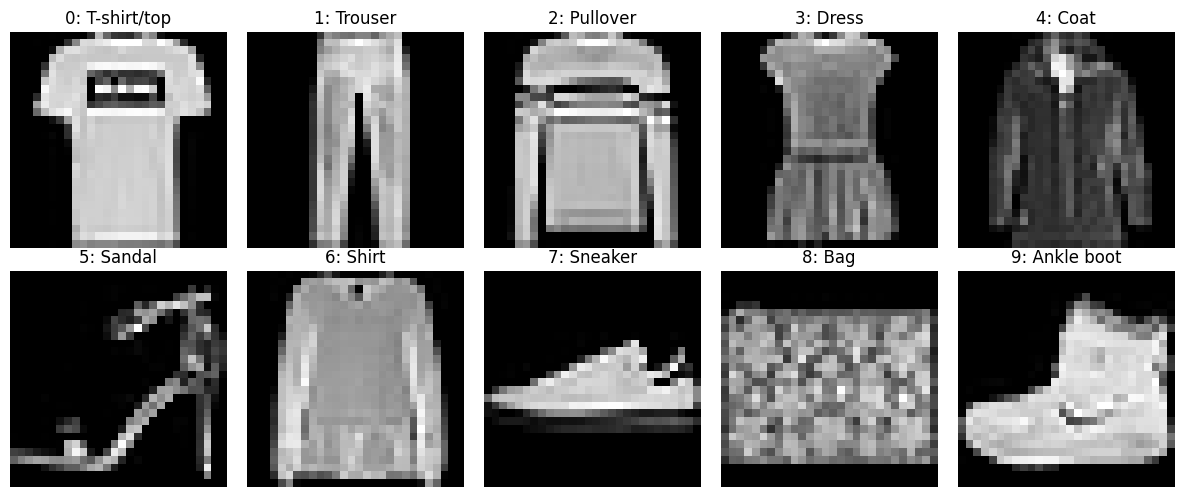

,class,count
0,T-shirt/top,6000
1,Trouser,6000
2,Pullover,6000
3,Dress,6000
4,Coat,6000
5,Sandal,6000
6,Shirt,6000
7,Sneaker,6000
8,Bag,6000
9,Ankle boot,6000


In [8]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for c, ax in enumerate(axes.ravel()):
    idx = np.where(y_train == c)[0][0]
    ax.imshow(X_train_img[idx], cmap="gray")
    ax.set_title(f"{c}: {class_names[c]}")
    ax.axis("off")
plt.tight_layout()
plt.show()
display(pd.DataFrame({"class": class_names, "count": np.bincount(y_train)}))

,Class,Number of Images
0,T-shirt/top,6000
1,Trouser,6000
2,Pullover,6000
3,Dress,6000
4,Coat,6000
5,Sandal,6000
6,Shirt,6000
7,Sneaker,6000
8,Bag,6000
9,Ankle boot,6000


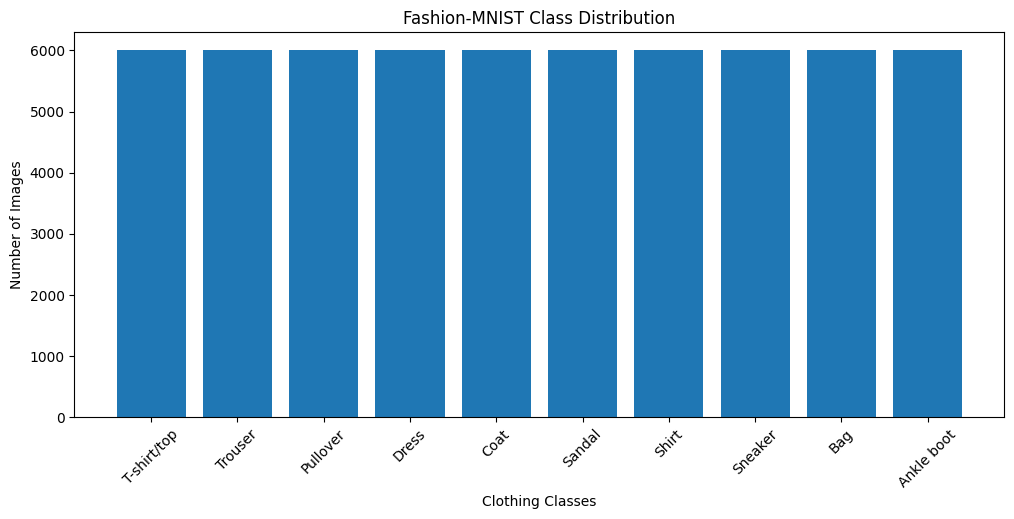

In [9]:
class_counts = pd.DataFrame({
    "Class": class_names,
    "Number of Images": np.bincount(y_train)
})

display(class_counts)

plt.figure(figsize=(12, 5))

plt.bar(class_names, np.bincount(y_train))

plt.xticks(rotation=45)

plt.xlabel("Clothing Classes")

plt.ylabel("Number of Images")

plt.title("Fashion-MNIST Class Distribution")

plt.show()

In [12]:
X_train_flat_all = X_train_img.reshape(
    len(X_train_img), -1
).astype(np.float32) / 255.0

X_test_flat = X_test_img.reshape(
    len(X_test_img), -1
).astype(np.float32) / 255.0

print("Training data shape:", X_train_flat_all.shape)

print("Testing data shape:", X_test_flat.shape)

Training data shape: (60000, 784)
Testing data shape: (10000, 784)


In [13]:
dev_indices, _ = train_test_split(
    np.arange(len(y_train)),
    train_size=20000,
    stratify=y_train,
    random_state=SEED
)

X_dev = X_train_flat_all[dev_indices]

X_dev_img = X_train_img[dev_indices]

y_dev = y_train[dev_indices]

print("Development dataset:", X_dev.shape)

print("Development labels:", y_dev.shape)

print("Class distribution:", np.bincount(y_dev))

Development dataset: (20000, 784)
Development labels: (20000,)
Class distribution: [2000 2000 2000 2000 2000 2000 2000 2000 2000 2000]


In [16]:
def extract_hog_features(images):

    features_list = []

    for image in images:

        features = hog(
            image,
            orientations=9,
            pixels_per_cell=(4, 4),
            cells_per_block=(2, 2),
            block_norm="L2-Hys",
            feature_vector=True
        )

        features_list.append(features)

    return np.asarray(features_list, dtype=np.float32)


start_time = time.time()

X_dev_hog = extract_hog_features(X_dev_img)

print("HOG feature extraction completed!")

print("HOG feature matrix:", X_dev_hog.shape)

HOG feature extraction completed!
HOG feature matrix: (20000, 1296)


In [17]:
def build_models():

    return {

        # Model 1
        "KNN - Raw Pixels":

        KNeighborsClassifier(
            n_neighbors=5,
            weights="distance",
            n_jobs=-1
        ),


        # Model 2
        "Linear SVM - Raw Pixels":

        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=SEED
        ),


        # Model 3
        "PCA + RBF SVM - Raw Pixels":

        Pipeline([
            ("pca", PCA(
                n_components=100,
                random_state=SEED
            )),

            ("svm", SVC(
                kernel="rbf",
                C=5.0,
                gamma="scale"
            ))
        ]),


        # Model 4
        "HOG + Linear SVM":

        LinearSVC(
            C=1.0,
            max_iter=5000,
            random_state=SEED
        ),


        # Model 5
        "HOG + PCA + Linear SVM":

        Pipeline([
            ("pca", PCA(
                n_components=100,
                random_state=SEED
            )),

            ("svm", LinearSVC(
                C=1.0,
                max_iter=5000,
                random_state=SEED
            ))
        ]),


        # Model 6 - Proposed Method
        "HOG + PCA + RBF SVM":

        Pipeline([
            ("pca", PCA(
                n_components=100,
                random_state=SEED
            )),

            ("svm", SVC(
                kernel="rbf",
                C=5.0,
                gamma="scale"
            ))
        ])
    }


X_for_method = {

    "KNN - Raw Pixels": X_dev,

    "Linear SVM - Raw Pixels": X_dev,

    "PCA + RBF SVM - Raw Pixels": X_dev,

    "HOG + Linear SVM": X_dev_hog,

    "HOG + PCA + Linear SVM": X_dev_hog,

    "HOG + PCA + RBF SVM": X_dev_hog

}

print("Six classification methods defined successfully!")

Six classification methods defined successfully!


In [18]:
N_SPLITS = 3

cv = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=SEED
)

cv_records = []

for name in build_models():

    print("\nRunning model:", name)

    X_current = X_for_method[name]

    for fold, (train_idx, val_idx) in enumerate(
        cv.split(X_dev, y_dev), start=1
    ):

        model = build_models()[name]

        X_train_fold = X_current[train_idx]

        X_val_fold = X_current[val_idx]

        y_train_fold = y_dev[train_idx]

        y_val_fold = y_dev[val_idx]

        start_time = time.time()

        model.fit(X_train_fold, y_train_fold)

        y_pred_fold = model.predict(X_val_fold)

        elapsed = time.time() - start_time

        accuracy = accuracy_score(
            y_val_fold,
            y_pred_fold
        )

        macro_f1 = f1_score(
            y_val_fold,
            y_pred_fold,
            average="macro"
        )

        macro_precision = precision_score(
            y_val_fold,
            y_pred_fold,
            average="macro",
            zero_division=0
        )

        macro_recall = recall_score(
            y_val_fold,
            y_pred_fold,
            average="macro",
            zero_division=0
        )

        cv_records.append({

            "Model": name,

            "Fold": fold,

            "Accuracy": accuracy,

            "Macro_F1": macro_f1,

            "Macro_Precision": macro_precision,

            "Macro_Recall": macro_recall,

            "Time_Seconds": elapsed

        })

        print(
            f"Fold {fold}: "
            f"Accuracy = {accuracy:.4f}, "
            f"Macro-F1 = {macro_f1:.4f}"
        )


cv_results = pd.DataFrame(cv_records)

display(cv_results)


Running model: KNN - Raw Pixels
Fold 1: Accuracy = 0.8352, Macro-F1 = 0.8350
Fold 2: Accuracy = 0.8308, Macro-F1 = 0.8306
Fold 3: Accuracy = 0.8275, Macro-F1 = 0.8278

Running model: Linear SVM - Raw Pixels
Fold 1: Accuracy = 0.8232, Macro-F1 = 0.8209
Fold 2: Accuracy = 0.8236, Macro-F1 = 0.8225
Fold 3: Accuracy = 0.8143, Macro-F1 = 0.8128

Running model: PCA + RBF SVM - Raw Pixels
Fold 1: Accuracy = 0.8796, Macro-F1 = 0.8791
Fold 2: Accuracy = 0.8847, Macro-F1 = 0.8839
Fold 3: Accuracy = 0.8806, Macro-F1 = 0.8806

Running model: HOG + Linear SVM
Fold 1: Accuracy = 0.8646, Macro-F1 = 0.8641
Fold 2: Accuracy = 0.8652, Macro-F1 = 0.8643
Fold 3: Accuracy = 0.8665, Macro-F1 = 0.8664

Running model: HOG + PCA + Linear SVM
Fold 1: Accuracy = 0.8655, Macro-F1 = 0.8639
Fold 2: Accuracy = 0.8614, Macro-F1 = 0.8596
Fold 3: Accuracy = 0.8572, Macro-F1 = 0.8560

Running model: HOG + PCA + RBF SVM
Fold 1: Accuracy = 0.8952, Macro-F1 = 0.8948
Fold 2: Accuracy = 0.8931, Macro-F1 = 0.8925
Fold 3: Acc

,Model,Fold,Accuracy,Macro_F1,Macro_Precision,Macro_Recall,Time_Seconds
0,KNN - Raw Pixels,1,0.835158,0.835001,0.839499,0.835182,13.159106
1,KNN - Raw Pixels,2,0.830808,0.830568,0.834296,0.830757,8.812500
2,KNN - Raw Pixels,3,0.827483,0.827833,0.832058,0.827516,6.933322
3,Linear SVM - Raw Pixels,1,0.823159,0.820868,0.820334,0.823197,28.003752
4,Linear SVM - Raw Pixels,2,0.823609,0.822463,0.821745,0.823547,27.163946
5,Linear SVM - Raw Pixels,3,0.814281,0.812813,0.812641,0.814317,26.673786
6,PCA + RBF SVM - Raw Pixels,1,0.879556,0.879133,0.879800,0.879590,23.446032
7,PCA + RBF SVM - Raw Pixels,2,0.884656,0.883893,0.883759,0.884605,17.625897
8,PCA + RBF SVM - Raw Pixels,3,0.880588,0.880628,0.880949,0.880605,11.762815
9,HOG + Linear SVM,1,0.864557,0.864105,0.863970,0.864595,20.448501


In [28]:
# Create a clean model comparison table

summary_clean = summary.reset_index()

# Select and rename columns
summary_clean = summary_clean[[
    "Model",
    "Accuracy_Mean",
    "Accuracy_Std",
    "Macro_F1_Mean",
    "Macro_F1_Std",
    "Precision_Mean",
    "Recall_Mean",
    "Average_Time"
]]

summary_clean.columns = [
    "Model",
    "Mean Accuracy",
    "Accuracy Std",
    "Mean Macro F1",
    "Macro F1 Std",
    "Mean Precision",
    "Mean Recall",
    "Average Time (Seconds)"
]

# Round numerical values
numeric_columns = summary_clean.select_dtypes(include="number").columns

summary_clean[numeric_columns] = summary_clean[numeric_columns].round(4)

# Display the table
display(summary_clean)

# Save as Excel
with pd.ExcelWriter("Fashion_MNIST_Model_Comparison.xlsx",
                    engine="openpyxl") as writer:

    summary_clean.to_excel(
        writer,
        sheet_name="Model Comparison",
        index=False
    )

    worksheet = writer.sheets["Model Comparison"]

    # Adjust column widths
    column_widths = {
        "A": 38,
        "B": 18,
        "C": 16,
        "D": 18,
        "E": 16,
        "F": 18,
        "G": 18,
        "H": 25
    }

    for column, width in column_widths.items():
        worksheet.column_dimensions[column].width = width

    # Make headings bold
    from openpyxl.styles import Font, Alignment

    for cell in worksheet[1]:
        cell.font = Font(bold=True)
        cell.alignment = Alignment(
            horizontal="center",
            vertical="center"
        )

    # Center numerical values
    for row in worksheet.iter_rows(min_row=2):
        for cell in row:
            cell.alignment = Alignment(
                horizontal="center",
                vertical="center"
            )

    # Freeze header row
    worksheet.freeze_panes = "A2"

    # Enable filters
    worksheet.auto_filter.ref = worksheet.dimensions

,Model,Mean Accuracy,Accuracy Std,Mean Macro F1,Macro F1 Std,Mean Precision,Mean Recall,Average Time (Seconds)
0,HOG + PCA + RBF SVM,0.8936,0.0014,0.8933,0.0014,0.8932,0.8936,12.0419
1,PCA + RBF SVM - Raw Pixels,0.8816,0.0027,0.8812,0.0024,0.8815,0.8816,17.6116
2,HOG + Linear SVM,0.8654,0.0010,0.8649,0.0013,0.8648,0.8654,20.5292
3,HOG + PCA + Linear SVM,0.8613,0.0041,0.8598,0.0039,0.8594,0.8613,5.3308
4,KNN - Raw Pixels,0.8311,0.0038,0.8311,0.0036,0.8353,0.8312,9.6350
5,Linear SVM - Raw Pixels,0.8203,0.0053,0.8187,0.0052,0.8182,0.8204,27.2805


In [22]:
best_model_name = summary.index[0]

print("Best model:", best_model_name)

print(
    "Best CV Macro-F1:",
    round(summary.iloc[0]["Macro_F1_Mean"], 4)
)


proposed_name = "HOG + PCA + RBF SVM"

print("\nProposed method performance:")

print(
    "HOG + PCA + RBF SVM , Macro-F1:",
    round(summary.loc[proposed_name, "Macro_F1_Mean"], 4)
)

Best model: HOG + PCA + RBF SVM
Best CV Macro-F1: 0.8933

Proposed method performance:
HOG + PCA + RBF SVM , Macro-F1: 0.8933


In [23]:
hog_methods = [
    "HOG + Linear SVM",
    "HOG + PCA + Linear SVM",
    "HOG + PCA + RBF SVM"
]

if best_model_name in hog_methods:

    print("Extracting HOG features from test images...")

    X_test_hog = extract_hog_features(X_test_img)

    X_final_train = X_dev_hog

    X_final_test = X_test_hog

else:

    X_final_train = X_dev

    X_final_test = X_test_flat


print("Final training matrix:", X_final_train.shape)

print("Final testing matrix:", X_final_test.shape)

Extracting HOG features from test images...
Final training matrix: (20000, 1296)
Final testing matrix: (10000, 1296)


In [24]:
final_model = build_models()[best_model_name]

start_time = time.time()

final_model.fit(
    X_final_train,
    y_dev
)

y_pred = final_model.predict(
    X_final_test
)

print(
    "Training and prediction time:",
    round((time.time() - start_time) / 60, 2),
    "minutes"
)


test_accuracy = accuracy_score(
    y_test,
    y_pred
)

test_macro_f1 = f1_score(
    y_test,
    y_pred,
    average="macro"
)

test_precision = precision_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)

test_recall = recall_score(
    y_test,
    y_pred,
    average="macro",
    zero_division=0
)


print("\nFINAL TEST RESULTS")

print("Selected model:", best_model_name)

print("Accuracy:", round(test_accuracy, 4))

print("Macro-F1:", round(test_macro_f1, 4))

print("Macro-Precision:", round(test_precision, 4))

print("Macro-Recall:", round(test_recall, 4))

Training and prediction time: 0.4 minutes

FINAL TEST RESULTS
Selected model: HOG + PCA + RBF SVM
Accuracy: 0.894
Macro-F1: 0.8941
Macro-Precision: 0.8942
Macro-Recall: 0.894


In [25]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

              precision    recall  f1-score   support

 T-shirt/top     0.8579    0.8450    0.8514      1000
     Trouser     0.9847    0.9670    0.9758      1000
    Pullover     0.8342    0.8300    0.8321      1000
       Dress     0.8871    0.9040    0.8955      1000
        Coat     0.8217    0.8390    0.8303      1000
      Sandal     0.9676    0.9560    0.9618      1000
       Shirt     0.7126    0.7090    0.7108      1000
     Sneaker     0.9309    0.9570    0.9438      1000
         Bag     0.9760    0.9770    0.9765      1000
  Ankle boot     0.9696    0.9560    0.9627      1000

    accuracy                         0.8940     10000
   macro avg     0.8942    0.8940    0.8941     10000
weighted avg     0.8942    0.8940    0.8941     10000



<Figure size 1200x900 with 0 Axes>

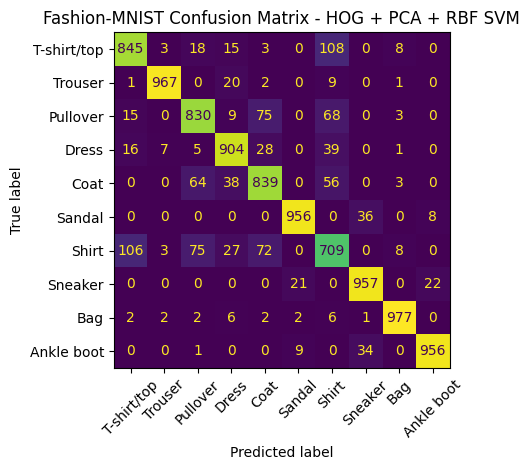

In [26]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(12, 9))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    xticks_rotation=45,
    values_format="d",
    colorbar=False
)

plt.title(
    "Fashion-MNIST Confusion Matrix - " + best_model_name
)

plt.tight_layout()

plt.show()

In [29]:
cv_results.to_csv(
    "fashion_mnist_cv_fold_results.csv",
    index=False
)

print("Cross-validation results saved!")

Cross-validation results saved!


In [30]:
summary.to_csv(
    "fashion_mnist_cv_summary.csv"
)

print("Model comparison summary saved!")

Model comparison summary saved!


In [31]:
predictions_df = pd.DataFrame({

    "true_label": y_test,

    "true_class": [
        class_names[int(i)] for i in y_test
    ],

    "predicted_label": y_pred,

    "predicted_class": [
        class_names[int(i)] for i in y_pred
    ],

    "correct": y_test == y_pred

})


predictions_df.to_csv(
    "fashion_mnist_test_predictions.csv",
    index=False
)

print("Test predictions saved!")

Test predictions saved!


In [32]:
report = classification_report(

    y_test,

    y_pred,

    target_names=class_names,

    output_dict=True,

    zero_division=0

)


report_df = pd.DataFrame(report).transpose()


report_df.to_csv(
    "fashion_mnist_test_classification_report.csv"
)

print("Classification report saved!")

Classification report saved!


In [33]:
final_metrics = pd.DataFrame([{

    "Selected_Model": best_model_name,

    "Test_Accuracy": test_accuracy,

    "Test_Macro_F1": test_macro_f1,

    "Test_Precision": test_precision,

    "Test_Recall": test_recall,

    "Development_Sample_Size": len(y_dev),

    "Official_Test_Size": len(y_test),

    "Cross_Validation_Folds": N_SPLITS,

    "Random_Seed": SEED

}])


final_metrics.to_csv(
    "fashion_mnist_final_metrics.csv",
    index=False
)


display(final_metrics)

print("Final metrics saved!")

,Selected_Model,Test_Accuracy,Test_Macro_F1,Test_Precision,Test_Recall,Development_Sample_Size,Official_Test_Size,Cross_Validation_Folds,Random_Seed
0,HOG + PCA + RBF SVM,0.894,0.894061,0.894236,0.894,20000,10000,3,42


Final metrics saved!


In [34]:
settings = {

    "Dataset": "Fashion-MNIST",

    "Development_Sample": 20000,

    "Official_Test_Size": 10000,

    "Cross_Validation": "Stratified 3-Fold",

    "HOG_Orientations": 9,

    "HOG_Pixels_Per_Cell": [4, 4],

    "HOG_Cells_Per_Block": [2, 2],

    "PCA_Components": 100,

    "Proposed_Method": "HOG + PCA + RBF SVM",

    "Selected_Model": best_model_name,

    "Random_Seed": SEED

}


with open(
    "fashion_mnist_experiment_settings.json",
    "w"
) as f:

    json.dump(settings, f, indent=4)


print("Experiment settings saved!")

Experiment settings saved!


In [35]:
result_files = [

    "fashion_mnist_cv_fold_results.csv",

    "fashion_mnist_cv_summary.csv",

    "fashion_mnist_test_predictions.csv",

    "fashion_mnist_test_classification_report.csv",

    "fashion_mnist_final_metrics.csv",

    "fashion_mnist_experiment_settings.json"

]


with zipfile.ZipFile(
    "fashion_mnist_results_bundle.zip",
    "w",
    zipfile.ZIP_DEFLATED
) as zip_file:

    for filename in result_files:

        zip_file.write(filename)


print("All result files combined successfully!")

print("\nGenerated files:")

for filename in result_files:

    print(filename)

print("\nZIP file:")

print("fashion_mnist_results_bundle.zip")

All result files combined successfully!

Generated files:
fashion_mnist_cv_fold_results.csv
fashion_mnist_cv_summary.csv
fashion_mnist_test_predictions.csv
fashion_mnist_test_classification_report.csv
fashion_mnist_final_metrics.csv
fashion_mnist_experiment_settings.json

ZIP file:
fashion_mnist_results_bundle.zip


In [36]:
from google.colab import files

files.download(
    "fashion_mnist_results_bundle.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>